# Model Validation on Real Data

Evaluate model performance using real-world data.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from gene_prevalence import BernoulliPrevalenceModel

In [2]:
# set aesthetic parameters

line_color = '#0F0A0A'    # dark

neutral_color = '#E0E0E0'

# thursday
accent_colors = ['#9B5DE5', '#FFAC69', '#00C9AE', '#FD3F92', '#0F0A0A', 
                 '#959AB1', '#FFDB66', '#63B9FF','#FFB1CA', '#4F1DD7']

style = {'axes.edgecolor': line_color,
         'axes.labelcolor': line_color,
         'text.color': line_color,
         'xtick.color': line_color,
         'ytick.color': line_color,
         'font.family': 'Helvetica',
         'font.Helvetica': ['Helvetica']}

palette = sns.color_palette(accent_colors)

sns.set_context('talk', rc={'lines.linewidth': 2})
sns.set_palette(palette)
sns.set_style('ticks', style)

plt.rcParams['legend.frameon'] = False
plt.rcParams['axes.spines.left'] = True
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.bottom'] = True
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['patch.linewidth'] = 0
plt.rcParams['patch.edgecolor'] = 'none'
plt.rcParams['savefig.dpi'] = 300

In [3]:
# Read in the clade-balanced dataset (both complete and incomplete genome subsets).

# directory paths
project_root = Path.cwd().resolve().parent
data_dir = project_root / "data"
subset_dir = data_dir / "subsets"

# presence/absence data from the complete genomes of the clade-balanced dataset
subset_pa_complete_df = pd.read_csv(
    subset_dir / "pro_presence_absence_data_complete_clade_balanced.csv",
    index_col=0,
).T

# presence/absence data from the incomplete genomes of the clade-balanced dataset
subset_pa_incomplete_df = pd.read_csv(
    subset_dir / "pro_presence_absence_data_incomplete_clade_balanced.csv",
    index_col=0,
).T

# metadata for the genomes in the clade-balanced dataset
genome_metadata_df = pd.read_csv(data_dir / "pro_pangenome_metadata.csv")
completeness_series = genome_metadata_df.set_index("genome")["completeness"] / 100

# mean copy number of each gene across the complete genomes in the clade-balanced dataset
count_df = pd.concat(
    [
        pd.read_csv(
            subset_dir / "pro_count_data_complete_clade_balanced.csv",
            index_col=0,
        ).T,
        pd.read_csv(
            subset_dir / "pro_count_data_incomplete_clade_balanced.csv",
            index_col=0,
        ).T,
    ],
    axis=0,
)
subset_mean_gene_count = count_df[count_df > 0].mean(axis=0)

# look at shapes of the presence/absence dataframes
subset_pa_complete_df.shape, subset_pa_incomplete_df.shape


((50, 52500), (50, 52500))

In [4]:
# Estimate prevalence in complete and incomplete genomes with the Bernoulli model.

# set significance level for confidence intervals
alpha = 0.05

# complete genomes
complete_model = BernoulliPrevalenceModel(
    data=subset_pa_complete_df,
    lambdas=completeness_series.loc[subset_pa_complete_df.index],
)
complete_fit = complete_model.fit(
    estimator="mle",
    interval_method="likelihood_ratio",
    alpha=alpha,
    clip=True,
)
pi_hat_complete = complete_fit.prevalence
ci_lower_complete, ci_upper_complete = complete_fit.confidence_interval()

# incomplete genomes
incomplete_model = BernoulliPrevalenceModel(
    data=subset_pa_incomplete_df,
    lambdas=completeness_series.loc[subset_pa_incomplete_df.index],
)
incomplete_fit = incomplete_model.fit(
    estimator="mle",
    interval_method="likelihood_ratio",
    alpha=alpha,
    clip=True,
)
pi_hat_incomplete = incomplete_fit.prevalence
ci_lower_incomplete, ci_upper_incomplete = incomplete_fit.confidence_interval()

mean_gene_count_bins = pd.cut(
    subset_mean_gene_count,
    bins=[0, 1, 1.5, 2, 3, 4, np.inf],
    labels=["1", "(1, 1.5]", "(1.5, 2]", "(2, 3]", "(3, 4]", ">4"],
)

estimate_df = pd.DataFrame(
    {
        "pi_hat_complete": pi_hat_complete, 
        "ci_upper_complete": ci_upper_complete,
        "ci_lower_complete": ci_lower_complete,
        "pi_hat_incomplete": pi_hat_incomplete,
        "ci_upper_incomplete": ci_upper_incomplete,
        "ci_lower_incomplete": ci_lower_incomplete,
        "pi_hat_diff": pi_hat_complete - pi_hat_incomplete,
        "mean_gene_copy": mean_gene_count_bins.loc[subset_pa_incomplete_df.columns],
    }
)

# drop genes with prevalence of 0 in both complete and incomplete genomes
estimate_df = estimate_df[~((estimate_df["pi_hat_complete"] == 0) & (estimate_df["pi_hat_incomplete"] == 0))]

estimate_df

,pi_hat_complete,ci_upper_complete,ci_lower_complete,pi_hat_incomplete,ci_upper_incomplete,ci_lower_incomplete,pi_hat_diff,mean_gene_copy
gene_cluster_id,,,,,,,,
GC_00000001,1.000000,1.000000,0.962314,1.000000,1.000000,0.950403,0.000000,>4
GC_00000002,1.000000,1.000000,0.962314,1.000000,1.000000,0.953751,0.000000,"(2, 3]"
GC_00000003,1.000000,1.000000,0.962314,1.000000,1.000000,0.943635,0.000000,"(2, 3]"
GC_00000004,1.000000,1.000000,0.962314,1.000000,1.000000,0.930825,0.000000,"(3, 4]"
GC_00000005,1.000000,1.000000,0.962314,1.000000,1.000000,0.946401,0.000000,"(1.5, 2]"
...,...,...,...,...,...,...,...,...
GC_00052821,0.000000,0.037689,0.000000,0.034772,0.147011,0.002006,-0.034772,1
GC_00052831,0.020002,0.085122,0.001152,0.000000,0.066593,0.000000,0.020002,1
GC_00052838,0.020002,0.085122,0.001152,0.000000,0.066593,0.000000,0.020002,1


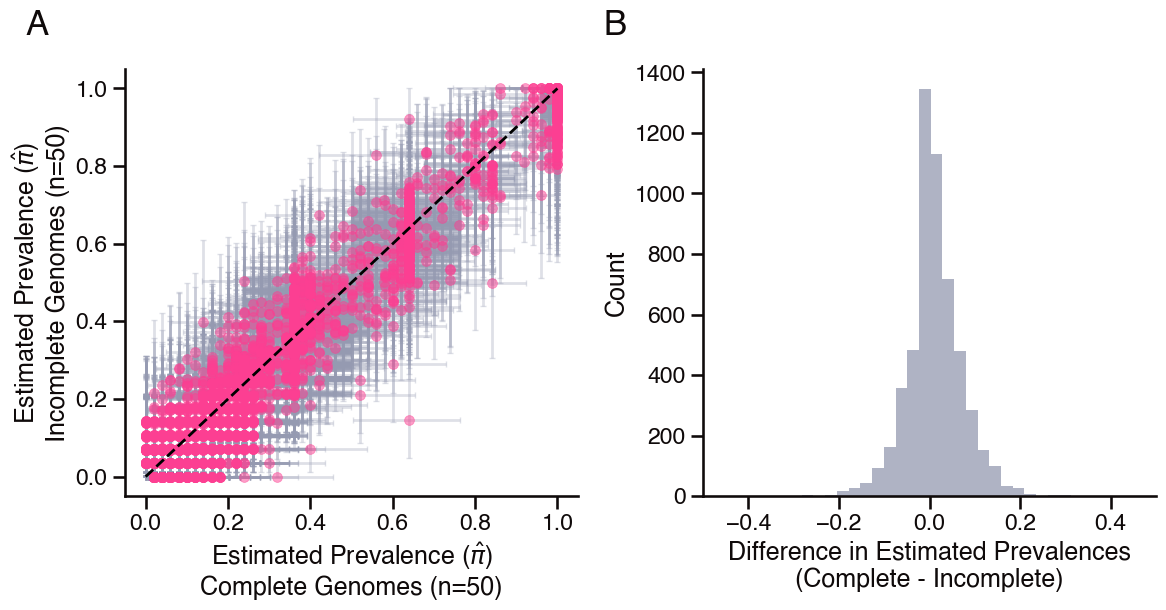

In [5]:
# plot the estimated prevalence in complete vs incomplete genomes
# along with confidence intervals as error bars
# second panel shows histogram of differences in prevalence estimates 
# (pi_hat_complete - pi_hat_incomplete)

# annotation specs
annotation_kwargs = dict(
    xy=(-0.22, 1.08),
    xycoords='axes fraction',
    fontsize=25,
    fontweight='bold'
)

# make figure
fig, ax = plt.subplots(1, 2, figsize=(12, 6.5))
sns.scatterplot(
    data=estimate_df,
    x="pi_hat_complete",
    y="pi_hat_incomplete",
    color=palette[3],
    s=50,
    alpha=0.5,
    edgecolor=None,
    zorder=2,
    ax=ax[0]
)

# add error bars 
ax[0].errorbar(
    x=estimate_df["pi_hat_complete"],
    y=estimate_df["pi_hat_incomplete"],
    xerr=[estimate_df["pi_hat_complete"] - estimate_df["ci_lower_complete"], 
          estimate_df["ci_upper_complete"] - estimate_df["pi_hat_complete"]],
    yerr=[estimate_df["pi_hat_incomplete"] - estimate_df["ci_lower_incomplete"], 
          estimate_df["ci_upper_incomplete"] - estimate_df["pi_hat_incomplete"]],
    fmt="none",
    ecolor=palette[5],
    capsize=2,
    alpha=0.3,
    zorder=1,  # put error bars behind points
)

# add a dashed diagonal line for reference
ax[0].plot([0, 1], [0, 1], "--", color="black", zorder=3)

# set range limits
maximum = max(
    estimate_df["pi_hat_complete"].max(),
    estimate_df["pi_hat_incomplete"].max(),
)
ax[0].set_xlim(-0.05, maximum + 0.05)
ax[0].set_ylim(-0.05, maximum + 0.05)

# labels
ax[0].set_xlabel(f"Estimated Prevalence ({r'$\hat{{\pi}}$'})\nComplete Genomes (n={subset_pa_complete_df.shape[0]})")
ax[0].set_ylabel(f"Estimated Prevalence ({r'$\hat{{\pi}}$'})\nIncomplete Genomes (n={subset_pa_incomplete_df.shape[0]})")
ax[0].annotate("A", **annotation_kwargs)

# plot histogram of differences in prevalence estimates 
# (exclude genes with zero prevalence in either dataset, 
# as well as genes with identical prevalence estimates in both datasets)
sns.histplot(
    data=estimate_df[(estimate_df["pi_hat_complete"] > 0) & (estimate_df["pi_hat_incomplete"] > 0) & (estimate_df["pi_hat_diff"] != 0)],
    x="pi_hat_diff",
    color=palette[5],
    bins=30,
    ax=ax[1]
)
ax[1].set_xlabel("Difference in Estimated Prevalences\n(Complete - Incomplete)")
ax[1].set_ylabel("Count")
ax[1].set_xlim(-0.5, 0.5)
ax[1].annotate("B", **annotation_kwargs)

plt.tight_layout()
plt.show()

Number of CIs narrower in incomplete genome estimates: 498
Number of CIs narrower in complete genome estimates: 5624


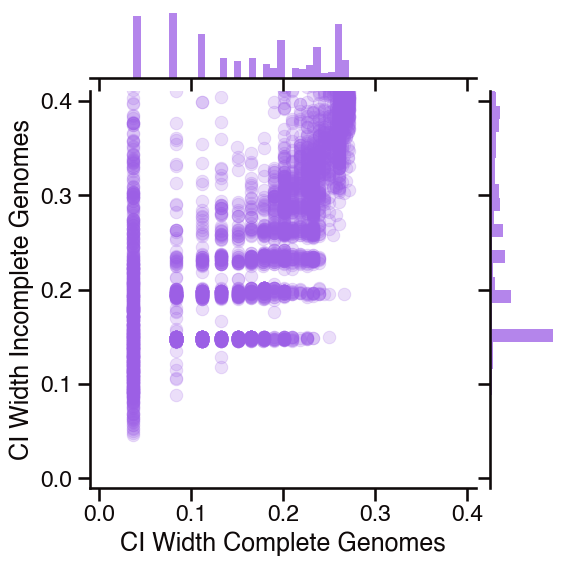

In [6]:
# look at distribution of interval widths for complete and incomplete genomes

# calculate confidence interval widths for complete and incomplete genome estimates
ci_width_complete = estimate_df["ci_upper_complete"] - estimate_df["ci_lower_complete"]
ci_width_incomplete = estimate_df["ci_upper_incomplete"] - estimate_df["ci_lower_incomplete"]

# remove CIs that come from genes with prevalence of 0 in either complete or incomplete genomes, since those CIs are not meaningful
ci_width_complete = ci_width_complete[~((estimate_df["pi_hat_complete"] == 0) | (estimate_df["pi_hat_incomplete"] == 0))]
ci_width_incomplete = ci_width_incomplete[~((estimate_df["pi_hat_complete"] == 0) | (estimate_df["pi_hat_incomplete"] == 0))]

# # look at log2 ratio of CI widths for incomplete vs complete genomes
# ci_width_ratio = np.log2(ci_width_incomplete / ci_width_complete)

# how man CIs are less in the incomplete genome estimates than in the complete genome estimates, and vice versa?
narrower_incomplete = (ci_width_incomplete < ci_width_complete).sum()
narrower_complete = (ci_width_complete < ci_width_incomplete).sum()
print(f"Number of CIs narrower in incomplete genome estimates: {narrower_incomplete}")
print(f"Number of CIs narrower in complete genome estimates: {narrower_complete}")

# make scatterplot with marginal histograms of CI widths for complete and incomplete genomes
sns.jointplot(
    x=ci_width_complete,
    y=ci_width_incomplete,
    kind="scatter",
    alpha=0.2,
    edgecolor=None,
    marginal_kws={"bins": 30, "fill": True},
)
plt.xlim(-0.01, 0.41)
plt.ylim(-0.01, 0.41)
plt.xlabel("CI Width Complete Genomes")
plt.ylabel("CI Width Incomplete Genomes")
plt.show()

In [7]:
# how many genes are detected in the complete vs incomplete genomes?

print("Number of genes detected in complete genomes:", (subset_pa_complete_df.sum(axis=0) > 0).sum())
print("Number of genes detected in incomplete genomes:", (subset_pa_incomplete_df.sum(axis=0) > 0).sum())
print("Number of genes detected in both complete and incomplete genomes:",
      ((subset_pa_complete_df.sum(axis=0) > 0) & (subset_pa_incomplete_df.sum(axis=0) > 0)).sum())
print("Number of genes detected in either complete or incomplete genomes:",
      ((subset_pa_complete_df.sum(axis=0) > 0) | (subset_pa_incomplete_df.sum(axis=0) > 0)).sum())
print("Number of genes detected in complete genomes but not incomplete genomes:",
      ((subset_pa_complete_df.sum(axis=0) > 0) & (subset_pa_incomplete_df.sum(axis=0) == 0)).sum())
print("Number of genes detected in incomplete genomes but not complete genomes:",
      ((subset_pa_complete_df.sum(axis=0) == 0) & (subset_pa_incomplete_df.sum(axis=0) > 0)).sum())


Number of genes detected in complete genomes: 10827
Number of genes detected in incomplete genomes: 9226
Number of genes detected in both complete and incomplete genomes: 6122
Number of genes detected in either complete or incomplete genomes: 13931
Number of genes detected in complete genomes but not incomplete genomes: 4705
Number of genes detected in incomplete genomes but not complete genomes: 3104


In [8]:
# what proportion of points fall within the confidence intervals of the other estimate?

within_ci_complete = (
    (estimate_df["pi_hat_incomplete"] >= estimate_df["ci_lower_complete"]) &
    (estimate_df["pi_hat_incomplete"] <= estimate_df["ci_upper_complete"])
)

within_ci_incomplete = (
    (estimate_df["pi_hat_complete"] >= estimate_df["ci_lower_incomplete"]) &
    (estimate_df["pi_hat_complete"] <= estimate_df["ci_upper_incomplete"])
)

print("Proportion of points where incomplete estimate is within complete CI: ", 
      f"{within_ci_complete.mean():.3f} +/- {2 * within_ci_complete.sem():.3f}")
print("Proportion of points where complete estimate is within incomplete CI: ", 
      f"{within_ci_incomplete.mean():.3f} +/- {2 * within_ci_incomplete.sem():.3f}")
print("Proportion of points where at least one estimate is within the other's CI: ", 
      f"{(within_ci_complete | within_ci_incomplete).mean():.3f} +/- {2 * (within_ci_complete | within_ci_incomplete).sem():.3f}")


Proportion of points where incomplete estimate is within complete CI:  0.594 +/- 0.008
Proportion of points where complete estimate is within incomplete CI:  0.754 +/- 0.007
Proportion of points where at least one estimate is within the other's CI:  0.966 +/- 0.003


In [9]:
# what's the proportion of genes in which the complete genome estimate is
# greter than vs less than the incomplete genome estimate, and vice versa?
# note that this should not include genes where either estimate is 0, 
# since those genes are not detected in one of the subsets and thus cannot be compared

nonzero_subset_df = estimate_df[
    (estimate_df["pi_hat_complete"] > 0) & 
    (estimate_df["pi_hat_incomplete"] > 0)
]   

proportion_complete_greater = (nonzero_subset_df["pi_hat_complete"] > nonzero_subset_df["pi_hat_incomplete"]).mean()
sem_complete_greater = np.sqrt(proportion_complete_greater * (1 - proportion_complete_greater) / len(nonzero_subset_df))
proportion_incomplete_greater = (nonzero_subset_df["pi_hat_incomplete"] > nonzero_subset_df["pi_hat_complete"]).mean()
sem_incomplete_greater = np.sqrt(proportion_incomplete_greater * (1 - proportion_incomplete_greater) / len(nonzero_subset_df))
proportion_equal = (nonzero_subset_df["pi_hat_complete"] == nonzero_subset_df["pi_hat_incomplete"]).mean()
sem_equal = np.sqrt(proportion_equal * (1 - proportion_equal) / len(nonzero_subset_df))

print("Proportion of detected genes where complete estimate "
      f"> incomplete estimate: {proportion_complete_greater:.3f} +/- {2 * sem_complete_greater:.3f}")
print("Proportion of detected genes where incomplete estimate "
      f"> complete estimate: {proportion_incomplete_greater:.3f} +/- {2 * sem_incomplete_greater:.3f}")
print("Proportion of detected genes where complete and incomplete "
      f"estimates are equal: {proportion_equal:.3f} +/- {2 * sem_equal:.3f}")


Proportion of detected genes where complete estimate > incomplete estimate: 0.489 +/- 0.013
Proportion of detected genes where incomplete estimate > complete estimate: 0.405 +/- 0.013
Proportion of detected genes where complete and incomplete estimates are equal: 0.107 +/- 0.008


In [10]:
# what's the range of predicted prevalence values in genes detected in incomplete
# genomes but not complete genomes?

# note: cloud genes are 15% prevalence or less, shell genes are 15-90% prevalence,
# and core genes are 90% prevalence or more

incomplete_not_complete = (subset_pa_complete_df.sum(axis=0) == 0) & (subset_pa_incomplete_df.sum(axis=0) > 0)
print("Range of predicted prevalence values in genes detected in incomplete genomes but not complete genomes:")
print("Complete genomes:")
print(f"  Min: {pi_hat_complete[incomplete_not_complete].min():.3f}")
print(f"  Max: {pi_hat_complete[incomplete_not_complete].max():.3f}")
print("Incomplete genomes:")
print(f"  Min: {pi_hat_incomplete[incomplete_not_complete].min():.3f}")
print(f"  Max: {pi_hat_incomplete[incomplete_not_complete].max():.3f}")

Range of predicted prevalence values in genes detected in incomplete genomes but not complete genomes:
Complete genomes:
  Min: 0.000
  Max: 0.000
Incomplete genomes:
  Min: 0.035
  Max: 0.143


### Performance at various confidence levels
- Look at proportion of genes for which the prevalence estimate from one population falls within the confidence interval of the estimate from the other population
- Compare this proportion to the confidence level across a range of different levels
- These numbers should track each other in a well-calibrated model with low bias

In [ ]:
# compile results at different significance levels for confidence intervals

# alpha_values = np.linspace(0.01, 0.99, 99)
alpha_values = np.array([0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])

# save results for each alpha value in a list of dictionaries
results = []
for a in alpha_values:
    ci_lower_complete, ci_upper_complete = complete_model.fit(
        estimator="mle",
        interval_method="likelihood_ratio",
        alpha=a,
        clip=True,
    ).confidence_interval()
    ci_lower_incomplete, ci_upper_incomplete = incomplete_model.fit(
        estimator="mle",
        interval_method="likelihood_ratio",
        alpha=a,
        clip=True,
    ).confidence_interval()
    
    # identify incomplete estimates that fall within the complete confidence intervals
    within_ci_complete = (
        (estimate_df["pi_hat_incomplete"] >= ci_lower_complete.loc[estimate_df.index]) &
        (estimate_df["pi_hat_incomplete"] <= ci_upper_complete.loc[estimate_df.index])
    )

    # identify complete estimates that fall within the incomplete confidence intervals
    within_ci_incomplete = (
        (estimate_df["pi_hat_complete"] >= ci_lower_incomplete.loc[estimate_df.index]) &
        (estimate_df["pi_hat_complete"] <= ci_upper_incomplete.loc[estimate_df.index])
    )

    # identify subset of genes that are detected in both datasets 
    # (i.e. have non-zero prevalence estimates in both complete and incomplete genomes)
    detected_in_both = estimate_df[
        (estimate_df["pi_hat_complete"] > 0) & (estimate_df["pi_hat_incomplete"] > 0)
    ].index

    # identify incomplete estimates that fall above and below the complete confidence intervals
    inc_above_ci_comp = estimate_df.loc[detected_in_both, "pi_hat_incomplete"] > ci_upper_complete.loc[detected_in_both]
    inc_below_ci_comp = estimate_df.loc[detected_in_both, "pi_hat_incomplete"] < ci_lower_complete.loc[detected_in_both]
    total_inc_outliers = inc_above_ci_comp.sum() + inc_below_ci_comp.sum()

    # identify complete estimates that fall above and below the incomplete confidence intervals
    comp_above_ci_inc = estimate_df.loc[detected_in_both, "pi_hat_complete"] > ci_upper_incomplete.loc[detected_in_both]
    comp_below_ci_inc = estimate_df.loc[detected_in_both, "pi_hat_complete"] < ci_lower_incomplete.loc[detected_in_both]
    total_comp_outliers = comp_above_ci_inc.sum() + comp_below_ci_inc.sum()

    results.append({
        "significance_level": a,
        "confidence_level": 1 - a,
        "pi_inc_within_ci_comp": within_ci_complete.mean(),
        "pi_comp_within_ci_inc": within_ci_incomplete.mean(),
        "within_either_ci": (within_ci_complete | within_ci_incomplete).mean(),
        "within_both_ci": (within_ci_complete & within_ci_incomplete).mean(),
        "pi_inc_outliers": total_inc_outliers,
        "pi_inc_above_ci_comp": inc_above_ci_comp.sum() / total_inc_outliers if total_inc_outliers > 0 else 0,
        "pi_comp_outliers": total_comp_outliers,
        "pi_comp_above_ci_inc": comp_above_ci_inc.sum() / total_comp_outliers if total_comp_outliers > 0 else 0,
    })

ci_results_df = pd.DataFrame(results)
ci_results_df


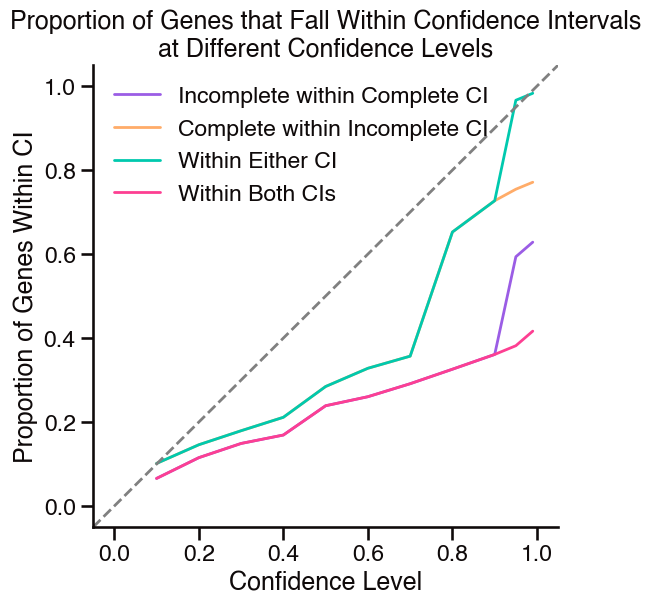

In [ ]:
# plot the confidence interval results

plt.figure(figsize=(6, 6))
sns.lineplot(data=ci_results_df, x="confidence_level", 
             y="pi_inc_within_ci_comp", label="Incomplete within Complete CI")
sns.lineplot(data=ci_results_df, x="confidence_level", 
             y="pi_comp_within_ci_inc", label="Complete within Incomplete CI")
sns.lineplot(data=ci_results_df, x="confidence_level", 
             y="within_either_ci", label="Within Either CI")
sns.lineplot(data=ci_results_df, x="confidence_level", 
             y="within_both_ci", label="Within Both CIs")
plt.xlabel("Confidence Level")
plt.ylabel("Proportion of Genes Within CI")
plt.title(
    "Proportion of Genes that Fall Within Confidence Intervals\n"
    "at Different Confidence Levels")
plt.legend()

# set limits to focus on the range of interest
range_min = -0.05
range_max = 1.05
plt.xlim(range_min, range_max)
plt.ylim(range_min, range_max)

# reference line where proportion = confidence level
plt.plot(
    [range_min, range_max], 
    [range_min, range_max], 
    "--", color="gray")

plt.show()

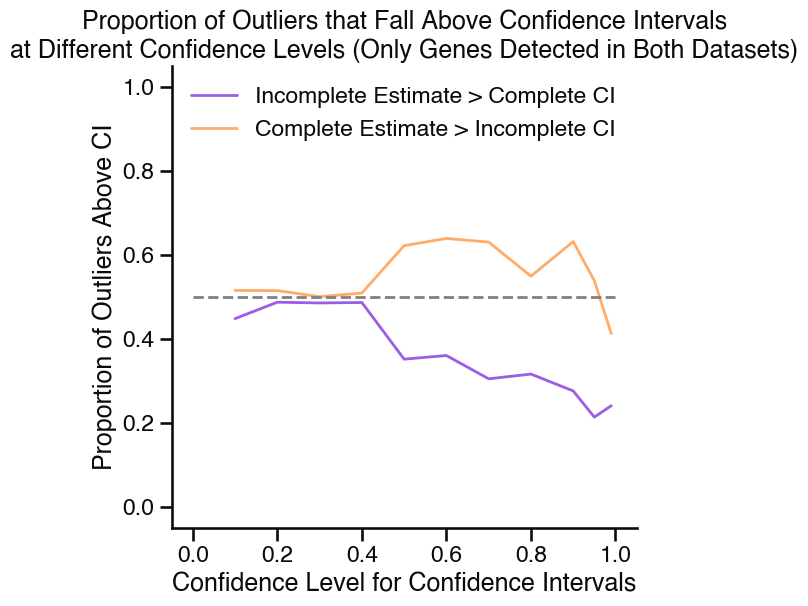

In [ ]:
# plot the proportion of outliers that fall above vs below the confidence intervals 
# at different significance levels

plt.figure(figsize=(6, 6))
sns.lineplot(data=ci_results_df, x="confidence_level", 
             y="pi_inc_above_ci_comp", label="Incomplete Estimate > Complete CI")
sns.lineplot(data=ci_results_df, x="confidence_level", 
             y="pi_comp_above_ci_inc", label="Complete Estimate > Incomplete CI")
plt.xlabel("Confidence Level for Confidence Intervals")
plt.ylabel("Proportion of Outliers Above CI")
plt.title(
    "Proportion of Outliers that Fall Above Confidence Intervals\n"
    "at Different Confidence Levels (Only Genes Detected in Both Datasets)")
plt.legend()

# set limits to focus on the range of interest
range_min = -0.05
range_max = 1.05
plt.xlim(range_min, range_max)
plt.ylim(range_min, range_max)

# add a reference line where proportion of outliers is equal above/below CI
plt.plot(
    [0, 1], 
    [0.5, 0.5], 
    "--", color="gray")

plt.show()

### Multicopy genes
- Look at performance specifically of multicopy genes

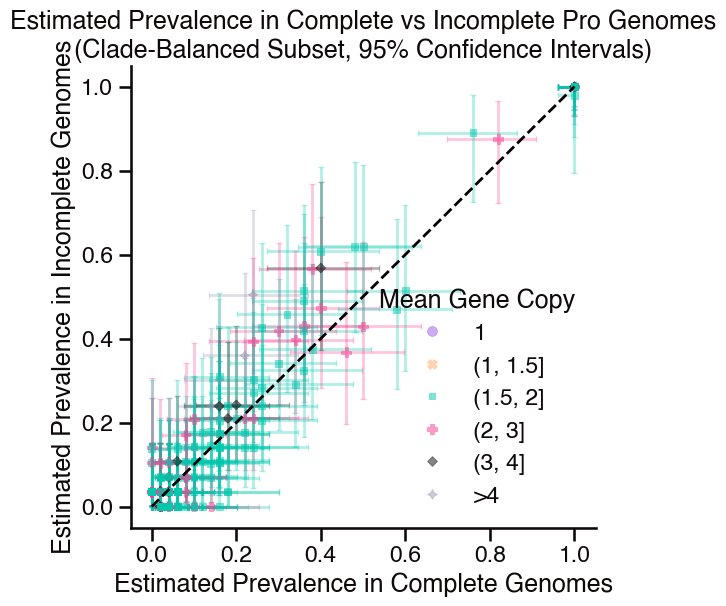

In [ ]:
# plot the estimated prevalence in complete vs incomplete genomes
# along with confidence intervals as error bars

# subset data to high copy number genes (mean copy number >= 1.5)
subset_estimate_df = estimate_df[
    # estimate_df["mean_gene_copy"].isin(["(1, 1.5]"])]
    estimate_df["mean_gene_copy"].isin(["(1.5, 2]", "(2, 3]", "(3, 4]", ">4"])]

# make colors for error bars match the points
hue_order = ["1", "(1, 1.5]", "(1.5, 2]", "(2, 3]", "(3, 4]", ">4"]
palette = sns.color_palette(n_colors=len(hue_order))
hue_to_color = dict(zip(hue_order, palette))

# make figure
plt.figure(figsize=(6, 6))
sns.scatterplot(
    data=subset_estimate_df,
    x="pi_hat_complete",
    y="pi_hat_incomplete",
    hue="mean_gene_copy",
    style="mean_gene_copy",
    s=50,
    alpha=0.5,
    edgecolor=None,
    zorder=2
)

# add error bars 
for i, row in subset_estimate_df.iterrows():
    plt.errorbar(
        x=row["pi_hat_complete"],
        y=row["pi_hat_incomplete"],
        xerr=[[row["pi_hat_complete"] - row["ci_lower_complete"]], 
              [row["ci_upper_complete"] - row["pi_hat_complete"]]],
        yerr=[[row["pi_hat_incomplete"] - row["ci_lower_incomplete"]], 
              [row["ci_upper_incomplete"] - row["pi_hat_incomplete"]]],
        fmt="none",
        ecolor=hue_to_color[str(row["mean_gene_copy"])],
        capsize=2,
        alpha=0.3,
        zorder=1,  # put error bars behind points
    )

# add a dashed diagonal line for reference
plt.plot([0, 1], [0, 1], "--", color="black", zorder=3)

# set range limits
maximum = max(
    subset_estimate_df["pi_hat_complete"].max(),
    subset_estimate_df["pi_hat_incomplete"].max(),
)
plt.xlim(-0.05, maximum + 0.05)
plt.ylim(-0.05, maximum + 0.05)

# add labels and title
plt.title(
    "Estimated Prevalence in Complete vs Incomplete Pro Genomes\n"
    f"(Clade-Balanced Subset, {int((1-alpha)*100)}% Confidence Intervals)"
)
plt.legend(title="Mean Gene Copy")
plt.xlabel("Estimated Prevalence in Complete Genomes")
plt.ylabel("Estimated Prevalence in Incomplete Genomes")
plt.show()

In [ ]:
# what's the proportion of genes in which the complete genome estimate is
# greter than vs less than the incomplete genome estimate, and vice versa?
# note that this should not include genes where either estimate is 0, 
# since those genes are not detected in one of the subsets and thus cannot be compared

nonzero_subset_df = subset_estimate_df[
    (subset_estimate_df["pi_hat_complete"] > 0) & 
    (subset_estimate_df["pi_hat_incomplete"] > 0)
]   

proportion_complete_greater = (nonzero_subset_df["pi_hat_complete"] > nonzero_subset_df["pi_hat_incomplete"]).mean()
proportion_incomplete_greater = (nonzero_subset_df["pi_hat_incomplete"] > nonzero_subset_df["pi_hat_complete"]).mean()
proportion_equal = (nonzero_subset_df["pi_hat_complete"] == nonzero_subset_df["pi_hat_incomplete"]).mean()

print("Proportion of detected genes where complete estimate "
      f"> incomplete estimate: {proportion_complete_greater:.2f}")
print("Proportion of detected genes where incomplete estimate "
      f"> complete estimate: {proportion_incomplete_greater:.2f}")
print("Proportion of detected genes where complete and incomplete "
      f"estimates are equal: {proportion_equal:.2f}")


Proportion of detected genes where complete estimate > incomplete estimate: 0.40
Proportion of detected genes where incomplete estimate > complete estimate: 0.51
Proportion of detected genes where complete and incomplete estimates are equal: 0.09


In [ ]:
# compile results at different confidence levels for high copy number genes 
# (mean copy number >= 1.5)

# subset data to high copy number genes (mean copy number >= 1.5)
subset_genes = subset_estimate_df.index

# set significance levels
# alpha_values = np.linspace(0.01, 0.99, 99)
alpha_values = np.array([0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])

# save results for each alpha value in a list of dictionaries
results = []
for a in alpha_values:
    ci_lower_complete, ci_upper_complete = complete_model.fit(
        estimator="mle",
        interval_method="likelihood_ratio",
        alpha=a,
        clip=True,
    ).confidence_interval()
    ci_lower_incomplete, ci_upper_incomplete = incomplete_model.fit(
        estimator="mle",
        interval_method="likelihood_ratio",
        alpha=a,
        clip=True,
    ).confidence_interval()
    
    # identify incomplete estimates that fall within the complete confidence intervals
    within_ci_complete = (
        (estimate_df.loc[subset_genes, "pi_hat_incomplete"] >= ci_lower_complete.loc[subset_genes]) &
        (estimate_df.loc[subset_genes, "pi_hat_incomplete"] <= ci_upper_complete.loc[subset_genes])
    )

    # identify complete estimates that fall within the incomplete confidence intervals
    within_ci_incomplete = (
        (estimate_df.loc[subset_genes, "pi_hat_complete"] >= ci_lower_incomplete.loc[subset_genes]) &
        (estimate_df.loc[subset_genes, "pi_hat_complete"] <= ci_upper_incomplete.loc[subset_genes])
    )

    results.append({
        "significance_level": a,
        "confidence_level": 1 - a,
        "pi_inc_within_ci_comp": within_ci_complete.mean(),
        "pi_comp_within_ci_inc": within_ci_incomplete.mean(),
        "within_either_ci": (within_ci_complete | within_ci_incomplete).mean(),
        "within_both_ci": (within_ci_complete & within_ci_incomplete).mean(),
    })

subset_ci_results_df = pd.DataFrame(results)
subset_ci_results_df


,significance_level,confidence_level,pi_inc_within_ci_comp,pi_comp_within_ci_inc,within_either_ci,within_both_ci
0,0.01,0.99,0.615094,0.841509,0.969811,0.486792
1,0.05,0.95,0.569811,0.807547,0.935849,0.441509
2,0.10,0.90,0.400000,0.758491,0.758491,0.400000
3,0.20,0.80,0.366038,0.652830,0.652830,0.366038
4,0.30,0.70,0.332075,0.384906,0.384906,0.332075
5,0.40,0.60,0.271698,0.358491,0.358491,0.271698
6,0.50,0.50,0.222642,0.294340,0.294340,0.222642
7,0.60,0.40,0.184906,0.218868,0.218868,0.184906
8,0.70,0.30,0.173585,0.192453,0.192453,0.173585
9,0.80,0.20,0.135849,0.166038,0.166038,0.135849


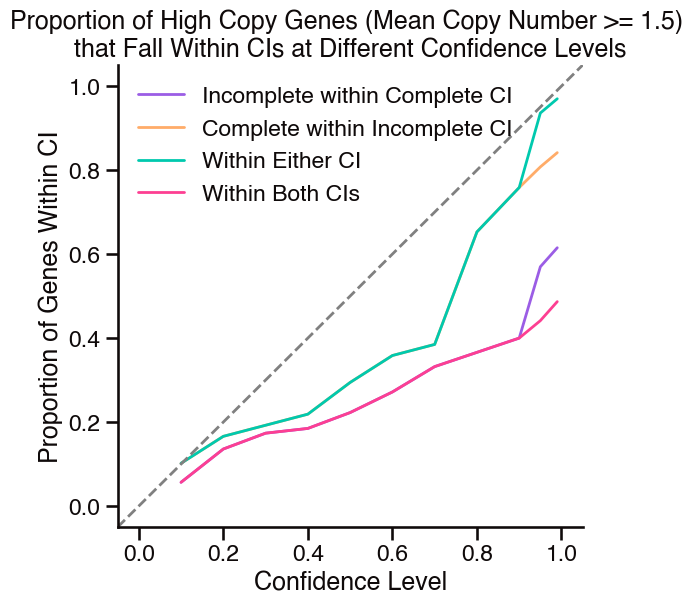

In [ ]:
# plot the subset confidence interval results

plt.figure(figsize=(6, 6))
sns.lineplot(data=subset_ci_results_df, x="confidence_level", 
             y="pi_inc_within_ci_comp", label="Incomplete within Complete CI")
sns.lineplot(data=subset_ci_results_df, x="confidence_level", 
             y="pi_comp_within_ci_inc", label="Complete within Incomplete CI")
sns.lineplot(data=subset_ci_results_df, x="confidence_level", 
             y="within_either_ci", label="Within Either CI")
sns.lineplot(data=subset_ci_results_df, x="confidence_level", 
             y="within_both_ci", label="Within Both CIs")
plt.xlabel("Confidence Level")
plt.ylabel("Proportion of Genes Within CI")
plt.title(
    "Proportion of High Copy Genes (Mean Copy Number >= 1.5) \n"
    "that Fall Within CIs at Different Confidence Levels")
plt.legend()

# set limits to focus on the range of interest
range_min = -0.05
range_max = 1.05
plt.xlim(range_min, range_max)
plt.ylim(range_min, range_max)

# reference line where proportion = confidence level
plt.plot(
    [range_min, range_max], 
    [range_min, range_max], 
    "--", color="gray")

plt.show()